<a href="https://colab.research.google.com/github/peimengsui/ml_from_scratch/blob/master/FlowMatchingDemo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F

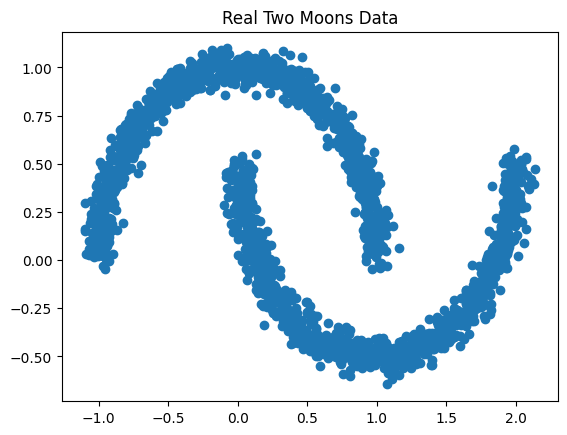

In [3]:
X, _ = make_moons(n_samples=2000, noise=0.05)
plt.scatter(X[:, 0], X[:, 1])
plt.title("Real Two Moons Data")
plt.show()

In [10]:
class TimeConditionedMLP(nn.Module):

  def __init__(self, data_dim=2, hidden_dim=128):
    super().__init__()

    self.net = nn.Sequential(
        nn.Linear(data_dim + 1, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, data_dim),
    )

  def forward(self, x_t, t):

    model_input = torch.cat([x_t, t], dim=-1)
    return self.net(model_input)

num_epochs = 100
batch_size = 128

dataset = torch.utils.data.TensorDataset(
    torch.tensor(X, dtype=torch.float)
)

dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
)

model = TimeConditionedMLP().cuda()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

model.train()

time_shift = 0.1
for epoch in range(num_epochs):
    for (x_data, ) in dataloader:

        x_data = x_data.cuda()
        t = torch.randn(x_data.shape[0], 1).cuda()
        t = torch.sigmoid(t)

        t = time_shift * t / (1 + (time_shift -1) * t)

        x_noise = torch.randn_like(x_data)
        x_t = (1-t) * x_data + t * x_noise

        v_pred = model(x_t, t)

        loss = F.mse_loss(v_pred, x_noise - x_data)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, Loss: {loss.item()}")


Epoch: 0, Loss: 1.4223729372024536
Epoch: 10, Loss: 1.3410660028457642
Epoch: 20, Loss: 1.2419371604919434
Epoch: 30, Loss: 0.9938515424728394
Epoch: 40, Loss: 0.8781373500823975
Epoch: 50, Loss: 0.9422544240951538
Epoch: 60, Loss: 1.0941287279129028
Epoch: 70, Loss: 0.9163719415664673
Epoch: 80, Loss: 0.957957923412323
Epoch: 90, Loss: 0.9692640900611877


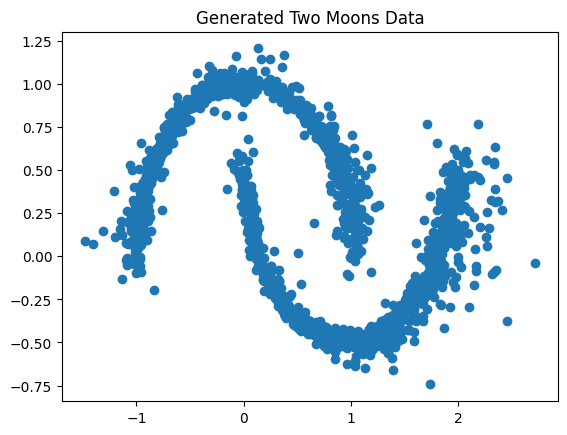

In [11]:
model.eval()

num_steps = 100
num_samples = 2000

x = torch.randn(num_samples, 2).cuda()

time_grid = torch.linspace(1, 0, num_steps+1).cuda()

with torch.no_grad():
    for i in range(num_steps):
        t = time_grid[i]
        t_next = time_grid[i+1]

        v = model(x, t.repeat(x.shape[0], 1))

        x = x - v * (t - t_next)

samples = x.cpu().numpy()
plt.scatter(samples[:, 0], samples[:, 1])
plt.title("Generated Two Moons Data")
plt.show()